# 🖼️ Görüntü İşleme (Image Processing) — Temelden İleriye Rehberi

Bu notebook, gerçek veri setleri kullanarak görüntü işlemenin temel kavramlarını adım adım öğretir.

---

## 📚 İçerik

| Bölüm | Konu |
|-------|------|
| 1 | Kurulum ve Veri Setleri |
| 2 | Görüntü Nedir? Piksel, Kanal, Boyut |
| 3 | Temel Görüntü Manipülasyonu |
| 4 | Renk Uzayları (RGB, Grayscale, HSV) |
| 5 | Histogram Analizi |
| 6 | Görüntü Filtreleme (Bulanıklaştırma, Keskinleştirme) |
| 7 | Kenar Tespiti (Edge Detection) |
| 8 | Morfolojik İşlemler |
| 9 | Eşikleme (Thresholding) |
| 10 | Kontur Tespiti |
| 11 | Özellik Çıkarımı ve Sınıflandırma |

> **Veri Setleri:**
> - **scipy.datasets.face** — gerçek bir rakun fotoğrafı (768×1024, RGB)
> - **scipy.datasets.ascent** — gri tonlamalı gerçek fotoğraf (512×512)
> - **sklearn digits** — 1797 adet gerçek el yazısı rakam görüntüsü (8×8)


## 🔧 Bölüm 1 — Kurulum ve Kütüphaneler

In [1]:
# Gerekli kütüphaneleri içe aktarıyoruz
import numpy as np                          # Sayısal dizi işlemleri için temel kütüphane
import matplotlib.pyplot as plt             # Grafik ve görüntü çizimi için
import matplotlib.gridspec as gridspec      # Karmaşık subplot düzeni için

import cv2                                  # OpenCV — görüntü işlemenin standart kütüphanesi
from PIL import Image, ImageFilter          # Pillow — Python'ın görüntü kütüphanesi
from PIL import ImageEnhance               # Parlaklık/kontrast ayarları için

from scipy import datasets as scd           # Scipy'den gerçek test görüntüleri
from scipy.ndimage import (                 # Scipy ile görüntü filtresi işlemleri
    gaussian_filter,
    sobel,
    median_filter
)

from sklearn.datasets import load_digits    # Sklearn'den el yazısı rakam veri seti
from sklearn.model_selection import train_test_split   # Eğitim/test bölme
from sklearn.preprocessing import StandardScaler        # Özellik normalizasyonu
from sklearn.neighbors import KNeighborsClassifier      # KNN sınıflandırıcı
from sklearn.metrics import classification_report, confusion_matrix  # Değerlendirme

import warnings
warnings.filterwarnings('ignore')           # Gereksiz uyarı mesajlarını gizle

# Matplotlib ayarları — retina ekranlar için yüksek DPI
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.family'] = 'DejaVu Sans'

print("✅ Tüm kütüphaneler başarıyla yüklendi!")
print(f"   NumPy:      {np.__version__}")
print(f"   OpenCV:     {cv2.__version__}")


✅ Tüm kütüphaneler başarıyla yüklendi!
   NumPy:      2.4.4
   OpenCV:     4.13.0


### 📥 Gerçek Veri Setlerini Yükle

In [2]:
# ── Veri Seti 1: Scipy Face (gerçek rakun fotoğrafı) ──────────────────────────
img_color = scd.face()                  # 768x1024 piksel, 3 kanal (RGB), uint8 formatı
print(f"Renkli görüntü (Face)  → şekil: {img_color.shape}, tip: {img_color.dtype}")

# ── Veri Seti 2: Scipy Ascent (gri tonlamalı gerçek fotoğraf) ─────────────────
img_gray_raw = scd.ascent()             # 512x512 piksel, tek kanal, uint8 formatı
print(f"Gri görüntü (Ascent)   → şekil: {img_gray_raw.shape}, tip: {img_gray_raw.dtype}")

# ── Veri Seti 3: Sklearn Digits (el yazısı rakamlar) ─────────────────────────
digits = load_digits()                  # 1797 adet 8x8 piksellik el yazısı rakam
X_digits = digits.images               # Görüntüler: (1797, 8, 8)
y_digits = digits.target               # Etiketler:  0-9 arası rakamlar
print(f"El yazısı rakamlar     → şekil: {X_digits.shape}, sınıf sayısı: {len(np.unique(y_digits))}")

# ── Gri görüntüyü numpy float64'e dönüştür ───────────────────────────────────
img_gray = img_gray_raw.astype(np.float64)   # float formatı filtre işlemlerinde gerekli

print("\n✅ Tüm veri setleri yüklendi!")


Renkli görüntü (Face)  → şekil: (768, 1024, 3), tip: uint8
Gri görüntü (Ascent)   → şekil: (512, 512), tip: uint8
El yazısı rakamlar     → şekil: (1797, 8, 8), sınıf sayısı: 10

✅ Tüm veri setleri yüklendi!


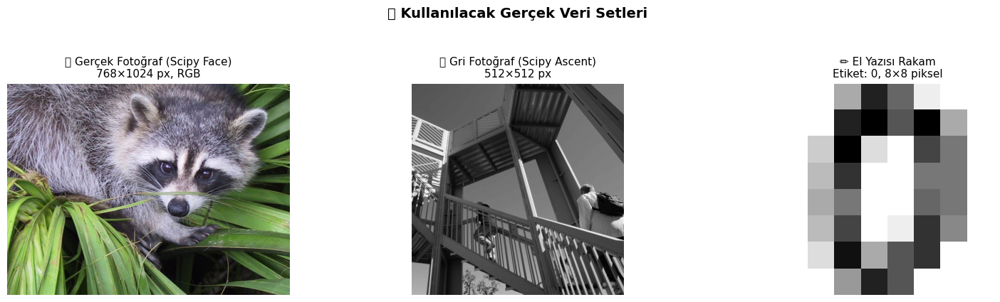

In [3]:
# Yüklenen veri setlerini görselleştirelim
fig, axes = plt.subplots(1, 3, figsize=(16, 4))   # 1 satır, 3 sütun grafik alanı

# ── Sol: Renkli Fotoğraf ──────────────────────────────────────────────────────
axes[0].imshow(img_color)               # RGB görüntüyü doğrudan göster
axes[0].set_title(f"🦝 Gerçek Fotoğraf (Scipy Face)\n{img_color.shape[0]}×{img_color.shape[1]} px, RGB", fontsize=11)
axes[0].axis('off')                     # Eksen çizgilerini gizle

# ── Orta: Gri Tonlamalı Fotoğraf ─────────────────────────────────────────────
axes[1].imshow(img_gray_raw, cmap='gray')   # Gri tonlama (tek kanal) için cmap='gray'
axes[1].set_title(f"⬛ Gri Fotoğraf (Scipy Ascent)\n{img_gray_raw.shape[0]}×{img_gray_raw.shape[1]} px", fontsize=11)
axes[1].axis('off')

# ── Sağ: El Yazısı Rakamlar Örnekleri ─────────────────────────────────────────
# 10 rakamdan birini göster (sınıf 0'ın ilk örneği)
sample_idx = 0                          # İlk görüntüyü seç
axes[2].imshow(X_digits[sample_idx], cmap='gray_r')  # Ters gri — siyah zemin üste beyaz
axes[2].set_title(f"✏️ El Yazısı Rakam\nEtiket: {y_digits[sample_idx]}, 8×8 piksel", fontsize=11)
axes[2].axis('off')

plt.suptitle("📂 Kullanılacak Gerçek Veri Setleri", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


## 🔬 Bölüm 2 — Görüntü Nedir? Piksel, Kanal, Boyut

### 📖 Teori

- **Piksel** (pixel): "picture element" — görüntünün en küçük birimi. Her piksel 0–255 arası bir sayıdır.
- **Kanal**: Renk boyutu. RGB görüntüde 3 kanal (Red, Green, Blue); gri görüntüde 1 kanal.
- **Shape** `(H, W, C)`: Yükseklik × Genişlik × Kanal sayısı
- **dtype**: Veri tipi. `uint8` → 0-255 tam sayı. `float32` → 0.0-1.0 ondalık.


In [4]:
# ── Görüntü boyutunu incele ───────────────────────────────────────────────────
H, W, C = img_color.shape              # shape tuple'ını açarak değişkenlere ata
print("=== Görüntü Boyut Bilgisi ===")
print(f"Yükseklik (H): {H} piksel")    # Satır sayısı
print(f"Genişlik  (W): {W} piksel")    # Sütun sayısı
print(f"Kanal sayısı : {C}  (RGB = 3 kanal)")
print(f"Toplam piksel: {H * W * C:,}")  # Toplam piksel sayısı (virgüllü format)
print(f"Veri tipi    : {img_color.dtype}")   # uint8 = 0-255 arası tam sayılar
print(f"Min değer    : {img_color.min()}")   # En karanlık piksel
print(f"Max değer    : {img_color.max()}")   # En parlak piksel
print(f"Ortalama     : {img_color.mean():.1f}")  # Ortalama parlaklık


=== Görüntü Boyut Bilgisi ===
Yükseklik (H): 768 piksel
Genişlik  (W): 1024 piksel
Kanal sayısı : 3  (RGB = 3 kanal)
Toplam piksel: 2,359,296
Veri tipi    : uint8
Min değer    : 0
Max değer    : 255
Ortalama     : 110.2


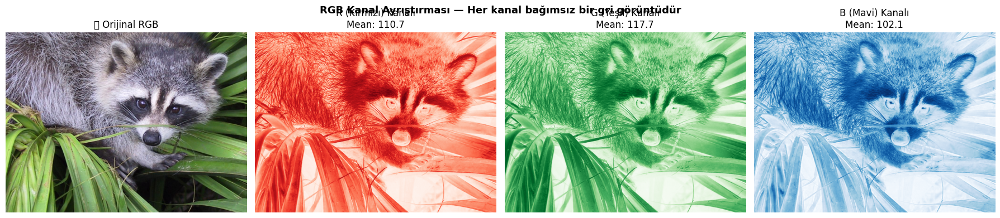

In [5]:
# ── RGB Kanallarını Ayrı Ayrı Görselleştir ────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Orijinal görüntü (tüm kanallar birlikte)
axes[0].imshow(img_color)
axes[0].set_title("🎨 Orijinal RGB")
axes[0].axis('off')

# Her kanal için renk haritası ve kanal adı
channel_info = [
    (img_color[:, :, 0], 'Reds',   'R (Kırmızı) Kanalı'),   # İndeks 0 = Red
    (img_color[:, :, 1], 'Greens', 'G (Yeşil) Kanalı'),     # İndeks 1 = Green
    (img_color[:, :, 2], 'Blues',  'B (Mavi) Kanalı'),       # İndeks 2 = Blue
]

for ax, (channel, cmap, title) in zip(axes[1:], channel_info):
    ax.imshow(channel, cmap=cmap)       # Tek kanalı seçili renk haritasıyla göster
    ax.set_title(f"{title}\nMean: {channel.mean():.1f}")
    ax.axis('off')

plt.suptitle("RGB Kanal Ayrıştırması — Her kanal bağımsız bir gri görüntüdür", 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


Belirli piksellerin RGB değerleri:
  Sol üst köşe    [0, 0]    : R=121, G=112, B=131
  Merkez          [384,512] : R=103, G=99, B=114
  Sağ alt köşe    [767,1023]: R=118, G=154, B=92

Kırpılan bölge şekli: (50, 50, 3)


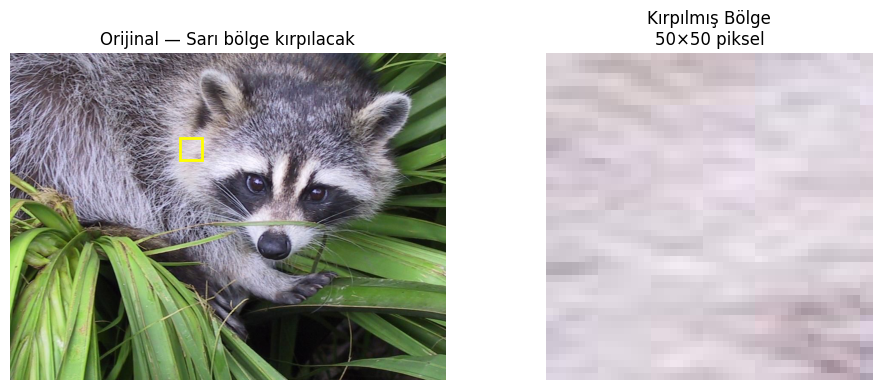

In [6]:
# ── Bireysel Piksel Değerlerini İncele ───────────────────────────────────────
print("Belirli piksellerin RGB değerleri:")
print(f"  Sol üst köşe    [0, 0]    : R={img_color[0, 0, 0]}, G={img_color[0, 0, 1]}, B={img_color[0, 0, 2]}")
print(f"  Merkez          [384,512] : R={img_color[384, 512, 0]}, G={img_color[384, 512, 1]}, B={img_color[384, 512, 2]}")
print(f"  Sağ alt köşe    [767,1023]: R={img_color[767, 1023, 0]}, G={img_color[767, 1023, 1]}, B={img_color[767, 1023, 2]}")

# Bir bölgeyi zoom ile göster (50x50 piksellik kırpma)
region = img_color[200:250, 400:450]    # [satır_başlangıç:bitiş, sütun_başlangıç:bitiş]
print(f"\nKırpılan bölge şekli: {region.shape}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.imshow(img_color)
rect = plt.Rectangle((400, 200), 50, 50, linewidth=2, edgecolor='yellow', facecolor='none')
ax1.add_patch(rect)                     # Seçilen bölgeyi dikdörtgenle işaretle
ax1.set_title("Orijinal — Sarı bölge kırpılacak")
ax1.axis('off')

ax2.imshow(region)
ax2.set_title(f"Kırpılmış Bölge\n{region.shape[0]}×{region.shape[1]} piksel")
ax2.axis('off')

plt.tight_layout()
plt.show()


## ✂️ Bölüm 3 — Temel Görüntü Manipülasyonu

Kırpma, yeniden boyutlandırma, döndürme, yatay/dikey çevirme.


Kırpma sonrası şekil: (400, 600, 3)
Küçültülmüş: (240, 320, 3)
Büyütülmüş : (600, 800, 3)


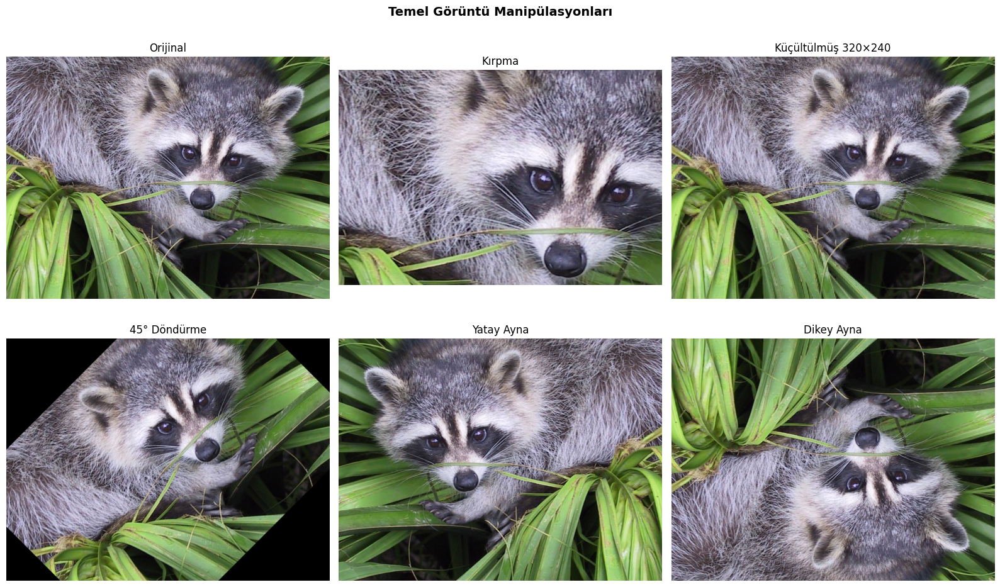

In [7]:
# ── Kırpma (Cropping) ─────────────────────────────────────────────────────────
# NumPy dilimleme ile basitçe yapılır: img[y_start:y_end, x_start:x_end]
crop = img_color[100:500, 200:800]      # Yükseklik: 100-500. Genişlik: 200-800
print(f"Kırpma sonrası şekil: {crop.shape}")   # (400, 600, 3)

# ── Yeniden Boyutlandırma (Resize) ────────────────────────────────────────────
# cv2.resize(img, (yeni_genislik, yeni_yukseklik)) — dikkat: genişlik önce gelir!
img_small  = cv2.resize(img_color, (320, 240))   # Küçült
img_large  = cv2.resize(img_color, (800, 600))   # Büyüt
print(f"Küçültülmüş: {img_small.shape}")
print(f"Büyütülmüş : {img_large.shape}")

# ── Döndürme (Rotation) ───────────────────────────────────────────────────────
# cv2 BGR formatı kullandığı için önce renk sırasını dönüştür
img_bgr = cv2.cvtColor(img_color, cv2.COLOR_RGB2BGR)  # RGB → BGR (OpenCV için)

h, w = img_bgr.shape[:2]               # Görüntü boyutlarını al
center = (w // 2, h // 2)             # Döndürme merkezi (genişlik/2, yükseklik/2)
M = cv2.getRotationMatrix2D(center, 45, 1.0)   # 45 derece, ölçek=1.0
img_rotated_bgr = cv2.warpAffine(img_bgr, M, (w, h))   # Dönüşümü uygula
img_rotated = cv2.cvtColor(img_rotated_bgr, cv2.COLOR_BGR2RGB)  # Tekrar RGB'ye çevir

# ── Yatay Çevirme (Horizontal Flip) ──────────────────────────────────────────
img_flip_h = np.fliplr(img_color)      # np.fliplr = sol-sağ çevirme (yatay ayna)

# ── Dikey Çevirme (Vertical Flip) ────────────────────────────────────────────
img_flip_v = np.flipud(img_color)      # np.flipud = yukarı-aşağı çevirme (dikey ayna)

# Hepsini görselleştir
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0,0].imshow(img_color);        axes[0,0].set_title("Orijinal");       axes[0,0].axis('off')
axes[0,1].imshow(crop);             axes[0,1].set_title("Kırpma");         axes[0,1].axis('off')
axes[0,2].imshow(img_small);        axes[0,2].set_title("Küçültülmüş 320×240"); axes[0,2].axis('off')
axes[1,0].imshow(img_rotated);      axes[1,0].set_title("45° Döndürme");   axes[1,0].axis('off')
axes[1,1].imshow(img_flip_h);       axes[1,1].set_title("Yatay Ayna");     axes[1,1].axis('off')
axes[1,2].imshow(img_flip_v);       axes[1,2].set_title("Dikey Ayna");     axes[1,2].axis('off')

plt.suptitle("Temel Görüntü Manipülasyonları", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🎨 Bölüm 4 — Renk Uzayları

| Renk Uzayı | Açıklama |
|------------|----------|
| **RGB** | Kırmızı, Yeşil, Mavi — insan ekranlarının dili |
| **Grayscale** | Tek kanal, 0-255 parlaklık |
| **HSV** | Ton (Hue), Doyma (Saturation), Değer (Value) — renk seçimi için ideal |
| **LAB** | Luminance + A + B — insan algısına yakın |


Grayscale şekli: (768, 1024)
Manuel grayscale farkı (max): 0.51
HSV şekli: (768, 1024, 3)
LAB şekli: (768, 1024, 3)


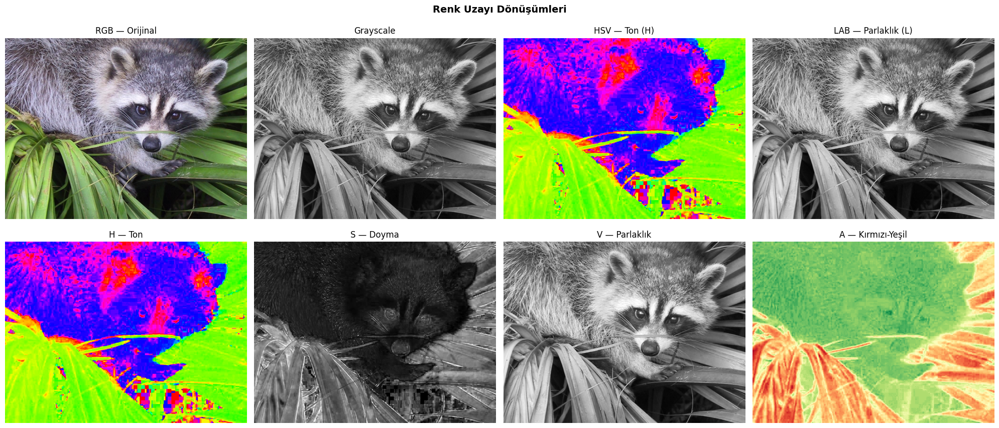

In [8]:
# ── RGB → Grayscale Dönüşümü ──────────────────────────────────────────────────
# Formül: Gray = 0.2989*R + 0.5870*G + 0.1140*B  (ağırlıklı ortalama)
gray = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)   # OpenCV dönüşümü
print(f"Grayscale şekli: {gray.shape}")               # (768, 1024) — kanal yok

# Manuel hesaplama (formülü görmek için):
gray_manual = (0.2989 * img_color[:,:,0] +     # Kırmızı katkısı (en az)
               0.5870 * img_color[:,:,1] +     # Yeşil katkısı (en fazla — insan gözü yeşile duyarlı)
               0.1140 * img_color[:,:,2])       # Mavi katkısı
print(f"Manuel grayscale farkı (max): {abs(gray.astype(float) - gray_manual).max():.2f}")

# ── RGB → HSV Dönüşümü ────────────────────────────────────────────────────────
# HSV: H=Ton(0-179°), S=Doyma(0-255), V=Parlaklık(0-255) — renk maskeleme için ideal
img_bgr_orig = cv2.cvtColor(img_color, cv2.COLOR_RGB2BGR)   # OpenCV BGR formatı ister
hsv = cv2.cvtColor(img_bgr_orig, cv2.COLOR_BGR2HSV)          # BGR → HSV
print(f"HSV şekli: {hsv.shape}")

# ── RGB → LAB Dönüşümü ────────────────────────────────────────────────────────
# LAB: L=Parlaklık, A=Kırmızı-Yeşil ekseni, B=Sarı-Mavi ekseni
lab = cv2.cvtColor(img_bgr_orig, cv2.COLOR_BGR2LAB)
print(f"LAB şekli: {lab.shape}")

# Görselleştir
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

# Üst satır: Görüntüler
axes[0,0].imshow(img_color);              axes[0,0].set_title("RGB — Orijinal");   axes[0,0].axis('off')
axes[0,1].imshow(gray, cmap='gray');      axes[0,1].set_title("Grayscale");        axes[0,1].axis('off')
axes[0,2].imshow(hsv[:,:,0], cmap='hsv');axes[0,2].set_title("HSV — Ton (H)");   axes[0,2].axis('off')
axes[0,3].imshow(lab[:,:,0], cmap='gray');axes[0,3].set_title("LAB — Parlaklık (L)"); axes[0,3].axis('off')

# Alt satır: HSV kanalları ayrıntılı
axes[1,0].imshow(hsv[:,:,0], cmap='hsv');  axes[1,0].set_title("H — Ton");         axes[1,0].axis('off')
axes[1,1].imshow(hsv[:,:,1], cmap='gray'); axes[1,1].set_title("S — Doyma");       axes[1,1].axis('off')
axes[1,2].imshow(hsv[:,:,2], cmap='gray'); axes[1,2].set_title("V — Parlaklık");   axes[1,2].axis('off')
axes[1,3].imshow(lab[:,:,1], cmap='RdYlGn'); axes[1,3].set_title("A — Kırmızı-Yeşil"); axes[1,3].axis('off')

plt.suptitle("Renk Uzayı Dönüşümleri", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


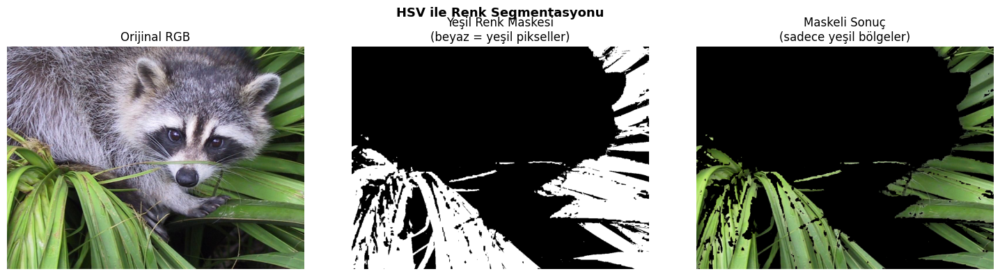

In [9]:
# ── Pratik Uygulama: HSV ile Renk Maskesi ─────────────────────────────────────
# HSV uzayı belirli bir rengi (örn. yeşil) kolayca seçmemizi sağlar

# Yeşil renk için HSV aralığı (H:40-80, S:50-255, V:50-255)
lower_green = np.array([40, 50, 50])     # Alt sınır: ton, doyma, parlaklık
upper_green = np.array([80, 255, 255])   # Üst sınır

mask = cv2.inRange(hsv, lower_green, upper_green)   # Aralıktaki pikseller 255, diğerleri 0

# Maskeyi orijinal görüntüye uygula
masked_bgr = cv2.bitwise_and(img_bgr_orig, img_bgr_orig, mask=mask)  # Sadece yeşil pikseller
masked_rgb = cv2.cvtColor(masked_bgr, cv2.COLOR_BGR2RGB)              # Görüntüleme için RGB'ye

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_color);       axes[0].set_title("Orijinal RGB");       axes[0].axis('off')
axes[1].imshow(mask, cmap='gray'); axes[1].set_title("Yeşil Renk Maskesi\n(beyaz = yeşil pikseller)"); axes[1].axis('off')
axes[2].imshow(masked_rgb);      axes[2].set_title("Maskeli Sonuç\n(sadece yeşil bölgeler)"); axes[2].axis('off')
plt.suptitle("HSV ile Renk Segmentasyonu", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 📊 Bölüm 5 — Histogram Analizi

**Histogram**: Bir görüntüdeki piksel yoğunluklarının dağılımını gösterir.
- X ekseni: Piksel değerleri (0-255)
- Y ekseni: O değere sahip piksel sayısı

Histogram eşitleme (equalization) düşük kontrastlı görüntüleri iyileştirir.


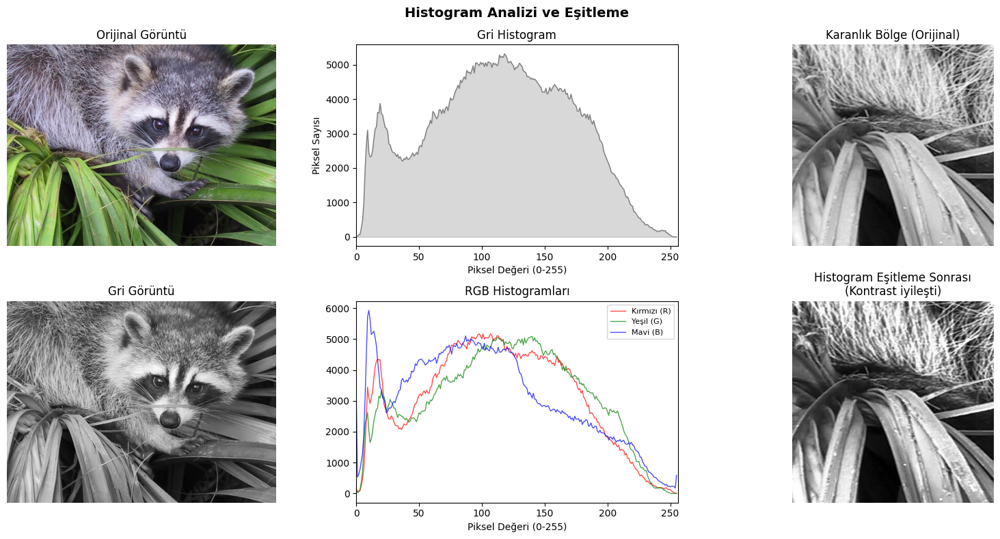

In [10]:
# ── Gri Tonlamalı Histogram ───────────────────────────────────────────────────
hist_gray, bins = np.histogram(gray.flatten(), 256, [0, 256])
# gray.flatten(): 2D diziyi tek boyutlu yap (tüm pikselleri listele)
# 256: 0-255 arası 256 kutu (bin) oluştur
# [0, 256]: değer aralığı

# ── RGB Kanalları için Histogramlar ──────────────────────────────────────────
colors = ['red', 'green', 'blue']       # Her kanal için renk
channel_names = ['Kırmızı (R)', 'Yeşil (G)', 'Mavi (B)']

fig = plt.figure(figsize=(16, 8))

# Sol üst: orijinal görüntü
ax1 = fig.add_subplot(2, 3, 1)
ax1.imshow(img_color)
ax1.set_title("Orijinal Görüntü")
ax1.axis('off')

# Sol alt: gri görüntü
ax2 = fig.add_subplot(2, 3, 4)
ax2.imshow(gray, cmap='gray')
ax2.set_title("Gri Görüntü")
ax2.axis('off')

# Orta üst: gri histogram
ax3 = fig.add_subplot(2, 3, 2)
ax3.plot(hist_gray, color='gray', linewidth=1)   # Histogram eğrisi
ax3.fill_between(range(256), hist_gray, alpha=0.3, color='gray')  # Alanı doldur
ax3.set_title("Gri Histogram")
ax3.set_xlabel("Piksel Değeri (0-255)")
ax3.set_ylabel("Piksel Sayısı")
ax3.set_xlim([0, 256])

# Orta alt: RGB Histogramları
ax4 = fig.add_subplot(2, 3, 5)
for i, (color, name) in enumerate(zip(colors, channel_names)):
    hist_c, _ = np.histogram(img_color[:,:,i].flatten(), 256, [0, 256])
    ax4.plot(hist_c, color=color, alpha=0.7, linewidth=1, label=name)
ax4.set_title("RGB Histogramları")
ax4.set_xlabel("Piksel Değeri (0-255)")
ax4.legend(fontsize=8)
ax4.set_xlim([0, 256])

# Sağ: Histogram Eşitleme
# Düşük kontrastlı bir bölge seç
dark_region = img_color[300:600, 100:400]   # Görece karanlık bölge
dark_gray = cv2.cvtColor(dark_region, cv2.COLOR_RGB2GRAY)
equalized = cv2.equalizeHist(dark_gray)     # Histogram eşitleme uygula

ax5 = fig.add_subplot(2, 3, 3)
ax5.imshow(dark_gray, cmap='gray')
ax5.set_title("Karanlık Bölge (Orijinal)")
ax5.axis('off')

ax6 = fig.add_subplot(2, 3, 6)
ax6.imshow(equalized, cmap='gray')
ax6.set_title("Histogram Eşitleme Sonrası\n(Kontrast iyileşti)")
ax6.axis('off')

plt.suptitle("Histogram Analizi ve Eşitleme", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🔄 Bölüm 6 — Görüntü Filtreleme

Filtreler görüntüdeki gürültüyü azaltır ya da kenarları vurgular.

**Konvolüsyon**: Küçük bir **kernel** (filtre matrisi) görüntü üzerinde kaydırılarak her piksel
yeniden hesaplanır.

```
Ortalama filtre (3×3):        Gaussian filtre (3×3):
┌───┬───┬───┐                 ┌───┬───┬───┐
│1/9│1/9│1/9│                 │ 1 │ 2 │ 1 │  / 16
│1/9│1/9│1/9│                 │ 2 │ 4 │ 2 │
│1/9│1/9│1/9│                 │ 1 │ 2 │ 1 │
└───┴───┴───┘                 └───┴───┴───┘
```


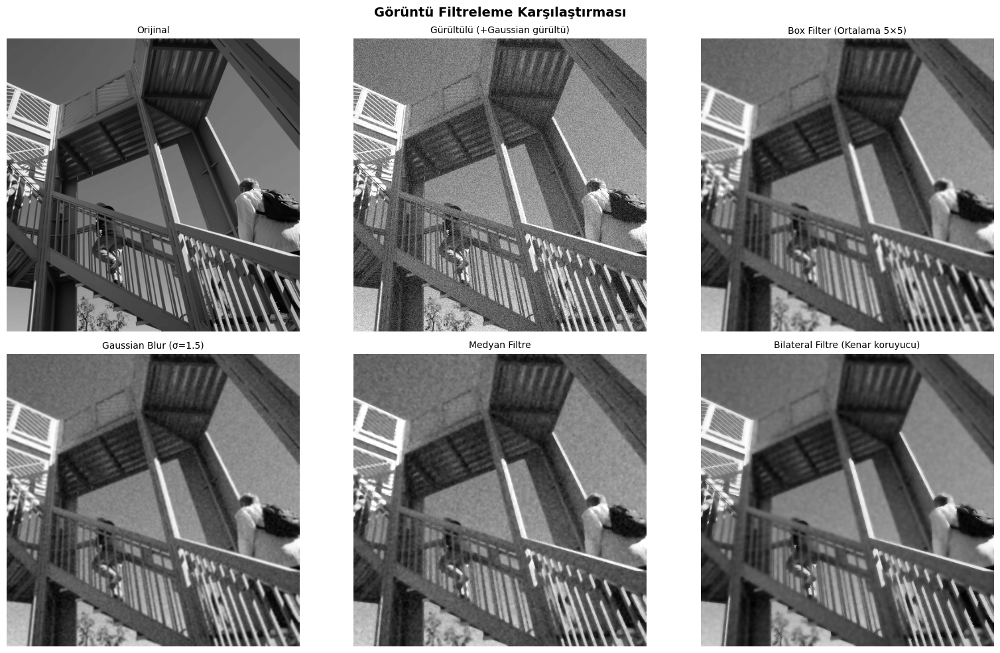

In [11]:
# Test için görüntüye gürültü ekle (gerçek hayatta kamera gürültüsü gibi)
rng = np.random.default_rng(42)          # Tekrar üretilebilir rastgele sayı üretici
noise = rng.integers(0, 60, img_gray_raw.shape, dtype=np.uint8)  # 0-60 arası gürültü
noisy = np.clip(img_gray_raw.astype(int) + noise, 0, 255).astype(np.uint8)  # Gürültü ekle

# ── 1. Ortalama (Box) Filtre ──────────────────────────────────────────────────
kernel_box = np.ones((5, 5), np.float32) / 25   # 5×5 kutu, her değer 1/25
blur_box = cv2.filter2D(noisy, -1, kernel_box)   # Konvolüsyon uygula

# ── 2. Gaussian Bulanıklaştırma ───────────────────────────────────────────────
# Gaussian: merkeze yakın piksellere daha fazla ağırlık verir (bell curve)
blur_gauss = cv2.GaussianBlur(noisy, (5, 5), sigmaX=1.5)  # 5x5 kernel, sigma=1.5

# ── 3. Medyan Filtre ──────────────────────────────────────────────────────────
# Her pikseli komşularının medyanıyla değiştirir — tuz-biber gürültüsüne en iyi
blur_median = cv2.medianBlur(noisy, 5)           # 5×5 pencerede medyan

# ── 4. Keskinleştirme (Sharpening) ────────────────────────────────────────────
kernel_sharp = np.array([[ 0, -1,  0],   # Laplacian tabanlı keskinleştirme kernel'i
                          [-1,  5, -1],   # Merkez pikseli güçlendir, komşuları zayıflat
                          [ 0, -1,  0]])
sharp = cv2.filter2D(img_gray_raw, -1, kernel_sharp)  # Keskin kenarlar ön plana çıkar

# ── 5. Bilateral Filtre ───────────────────────────────────────────────────────
# Kenarları koruyarak gürültü azaltır (edge-preserving blur)
bilateral = cv2.bilateralFilter(noisy, d=9, sigmaColor=75, sigmaSpace=75)
# d: komşuluk çapı, sigmaColor: renk benzerlik eşiği, sigmaSpace: mekan etkisi

# Tümünü görselleştir
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

imgs = [img_gray_raw, noisy, blur_box, blur_gauss, blur_median, bilateral]
titles = [
    "Orijinal", 
    "Gürültülü (+Gaussian gürültü)",
    "Box Filter (Ortalama 5×5)",
    "Gaussian Blur (σ=1.5)",
    "Medyan Filtre",
    "Bilateral Filtre (Kenar koruyucu)"
]

for ax, img, title in zip(axes.flatten(), imgs, titles):
    ax.imshow(img, cmap='gray')
    ax.set_title(title, fontsize=10)
    ax.axis('off')

plt.suptitle("Görüntü Filtreleme Karşılaştırması", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [12]:
# ── PSNR (Peak Signal-to-Noise Ratio) — Filtre kalitesini ölç ─────────────────
# PSNR ne kadar yüksekse filtre o kadar başarılı gürültü temizledi demektir

def calculate_psnr(original, filtered):
    """PSNR hesapla: Orijinal ve filtrelenmiş görüntüyü karşılaştır."""
    mse = np.mean((original.astype(float) - filtered.astype(float)) ** 2)  # Ortalama kare hata
    if mse == 0:
        return float('inf')                # MSE=0 ise mükemmel eşleşme
    max_pixel = 255.0                      # Maksimum piksel değeri
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))  # PSNR formülü (dB cinsinden)
    return psnr

filters = {
    'Box Filter'      : blur_box,
    'Gaussian Blur'   : blur_gauss,
    'Medyan Filtre'   : blur_median,
    'Bilateral Filtre': bilateral,
}

print("=== PSNR Karşılaştırması (dB) ===")
print(f"{'Filtre':<20} {'PSNR (dB)':>10}")
print("-" * 32)
for name, filtered in filters.items():
    psnr = calculate_psnr(img_gray_raw, filtered)
    bar = "█" * int(psnr / 2)             # Görsel çubuk
    print(f"{name:<20} {psnr:>8.2f} dB  {bar}")
print("\nNot: Daha yüksek PSNR = Orjinale daha yakın (iyi) filtreleme")


=== PSNR Karşılaştırması (dB) ===
Filtre                PSNR (dB)
--------------------------------
Box Filter              17.73 dB  ████████
Gaussian Blur           17.98 dB  ████████
Medyan Filtre           17.89 dB  ████████
Bilateral Filtre        18.12 dB  █████████

Not: Daha yüksek PSNR = Orjinale daha yakın (iyi) filtreleme


## 🔍 Bölüm 7 — Kenar Tespiti (Edge Detection)

**Kenar**: Piksel yoğunluğunun ani değiştiği yer — nesnelerin sınırları.

| Algoritma | Nasıl Çalışır |
|-----------|---------------|
| **Sobel** | X ve Y yönünde gradyan hesaplar |
| **Laplacian** | İkinci türev — tüm yönlerde kenar |
| **Canny** | Çok aşamalı; en güvenilir yöntem |


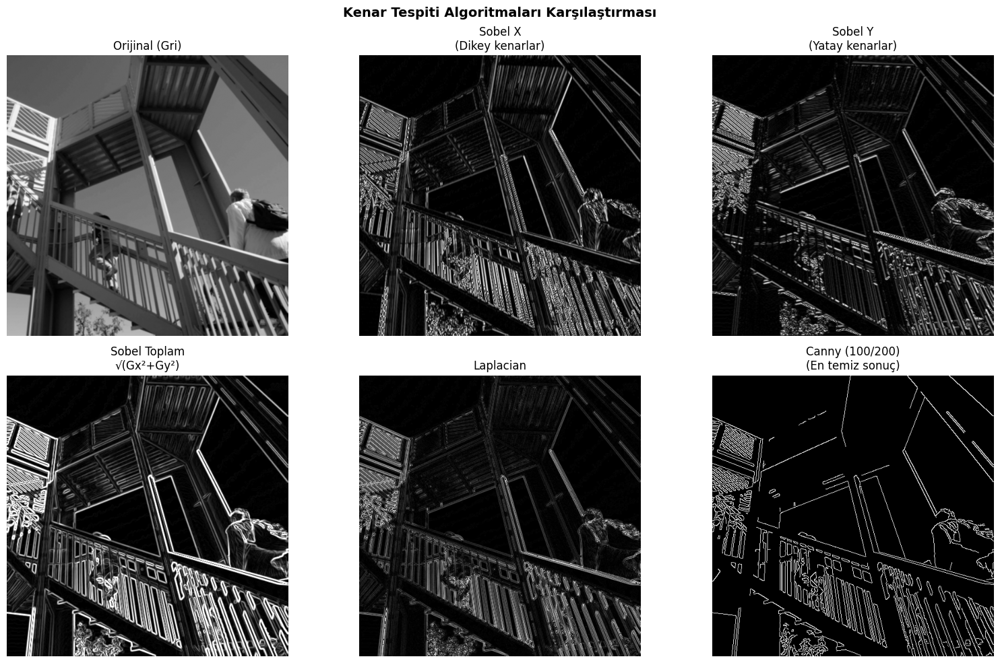

In [13]:
# Kenar tespiti için gürültüsüz görüntü kullan
test_img = cv2.GaussianBlur(img_gray_raw, (3, 3), 0)  # Önce hafif blur uygula

# ── 1. Sobel Kenar Dedektörü ──────────────────────────────────────────────────
# Sobel X: Dikey kenarlara duyarlı (yatay gradyan)
sobel_x = cv2.Sobel(test_img, cv2.CV_64F, 1, 0, ksize=3)   # dx=1, dy=0 → yatay değişim
# Sobel Y: Yatay kenarlara duyarlı (dikey gradyan)
sobel_y = cv2.Sobel(test_img, cv2.CV_64F, 0, 1, ksize=3)   # dx=0, dy=1 → dikey değişim
# Toplam Sobel: iki yönün karekök karesi
sobel_total = np.sqrt(sobel_x**2 + sobel_y**2)              # Gradyan büyüklüğü
sobel_total = np.clip(sobel_total, 0, 255).astype(np.uint8) # 0-255 aralığına sıkıştır

# ── 2. Laplacian Kenar Dedektörü ──────────────────────────────────────────────
# İkinci türev: tüm yönlerdeki kenarları aynı anda yakalar
laplacian = cv2.Laplacian(test_img, cv2.CV_64F, ksize=3)     # 3×3 Laplacian kernel
laplacian_abs = np.abs(laplacian).astype(np.uint8)            # Mutlak değer al

# ── 3. Canny Kenar Dedektörü ──────────────────────────────────────────────────
# Adımlar: Gaussian → Gradyan → Non-max suppression → Hysteresis thresholding
# threshold1: zayıf kenar eşiği, threshold2: güçlü kenar eşiği
canny_strict = cv2.Canny(test_img, threshold1=100, threshold2=200)  # Katı eşik
canny_loose  = cv2.Canny(test_img, threshold1=30,  threshold2=100)  # Gevşek eşik

# Görselleştir
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0,0].imshow(test_img, cmap='gray');     axes[0,0].set_title("Orijinal (Gri)");      axes[0,0].axis('off')
axes[0,1].imshow(np.abs(sobel_x).astype(np.uint8), cmap='gray'); axes[0,1].set_title("Sobel X\n(Dikey kenarlar)"); axes[0,1].axis('off')
axes[0,2].imshow(np.abs(sobel_y).astype(np.uint8), cmap='gray'); axes[0,2].set_title("Sobel Y\n(Yatay kenarlar)"); axes[0,2].axis('off')
axes[1,0].imshow(sobel_total, cmap='gray');  axes[1,0].set_title("Sobel Toplam\n√(Gx²+Gy²)"); axes[1,0].axis('off')
axes[1,1].imshow(laplacian_abs, cmap='gray');axes[1,1].set_title("Laplacian");             axes[1,1].axis('off')
axes[1,2].imshow(canny_strict, cmap='gray'); axes[1,2].set_title("Canny (100/200)\n(En temiz sonuç)"); axes[1,2].axis('off')

plt.suptitle("Kenar Tespiti Algoritmaları Karşılaştırması", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🔲 Bölüm 8 — Morfolojik İşlemler

İkili (binary) görüntülerdeki şekilleri düzeltmek için kullanılır.

| İşlem | Etki |
|-------|------|
| **Erosion** (aşındırma) | Şekli küçültür, ince gürültüyü siler |
| **Dilation** (genişletme) | Şekli büyütür, delikleri kapatır |
| **Opening** | Erosion → Dilation → Gürültü temizleme |
| **Closing** | Dilation → Erosion → Delik kapatma |


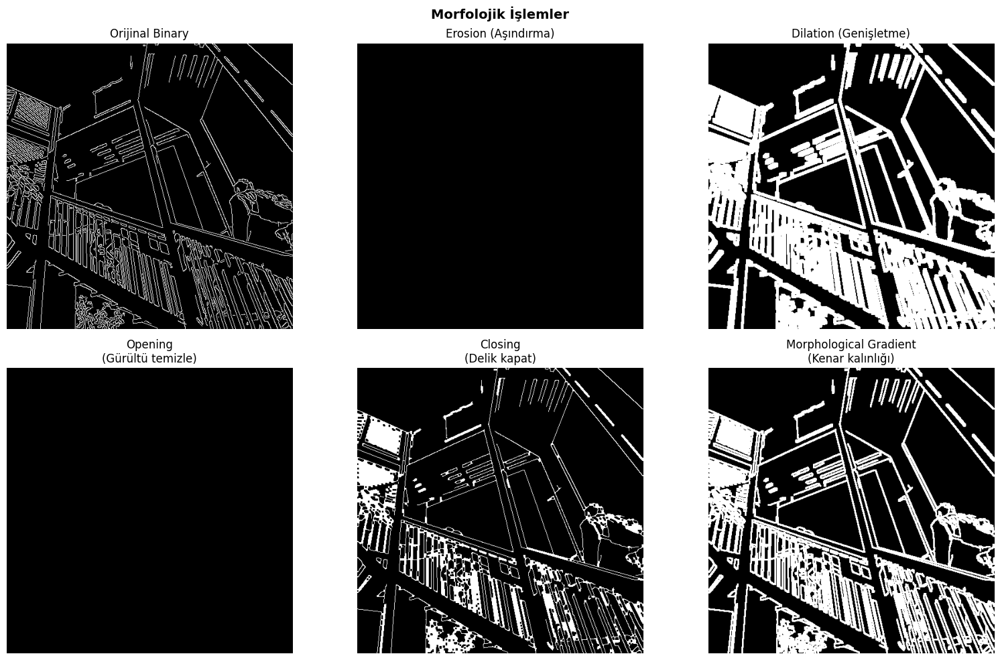

In [14]:
# Önce Canny ile ikili (binary) görüntü elde edelim
binary = cv2.Canny(test_img, 50, 150)   # Siyah-beyaz kenar haritası

# ── Yapısal Element (Kernel) ──────────────────────────────────────────────────
# Morfolojik işlemlerin uygulanacağı şekil penceresi
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))  # 3×3 kare kernel
# Alternatifleri: MORPH_ELLIPSE (daire), MORPH_CROSS (artı işareti)

# ── Erosion: Aşındırma ────────────────────────────────────────────────────────
# Piksel ancak kernel'deki TÜM pikseller beyazsa beyaz kalır → ince çizgiler yok olur
erosion = cv2.erode(binary, kernel, iterations=2)   # 2 kez uygula

# ── Dilation: Genişletme ──────────────────────────────────────────────────────
# Piksel kernel'deki HERHANGİ BİR piksel beyazsa beyaz olur → şekiller büyür
dilation = cv2.dilate(binary, kernel, iterations=2)  # 2 kez uygula

# ── Opening: Açma (Erosion + Dilation) ───────────────────────────────────────
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)   # Küçük gürültüyü siler

# ── Closing: Kapama (Dilation + Erosion) ─────────────────────────────────────
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)  # Küçük delikleri kapatır

# ── Gradient: Kenar kalınlığı ─────────────────────────────────────────────────
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)  # Dilation - Erosion

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0,0].imshow(binary,   cmap='gray'); axes[0,0].set_title("Orijinal Binary");     axes[0,0].axis('off')
axes[0,1].imshow(erosion,  cmap='gray'); axes[0,1].set_title("Erosion (Aşındırma)");  axes[0,1].axis('off')
axes[0,2].imshow(dilation, cmap='gray'); axes[0,2].set_title("Dilation (Genişletme)");axes[0,2].axis('off')
axes[1,0].imshow(opening,  cmap='gray'); axes[1,0].set_title("Opening\n(Gürültü temizle)"); axes[1,0].axis('off')
axes[1,1].imshow(closing,  cmap='gray'); axes[1,1].set_title("Closing\n(Delik kapat)");     axes[1,1].axis('off')
axes[1,2].imshow(gradient, cmap='gray'); axes[1,2].set_title("Morphological Gradient\n(Kenar kalınlığı)"); axes[1,2].axis('off')

plt.suptitle("Morfolojik İşlemler", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## ⚖️ Bölüm 9 — Eşikleme (Thresholding)

Gri görüntüyü ikili (siyah-beyaz) görüntüye dönüştürür.

- **Global eşikleme**: Tüm görüntü için tek bir eşik değeri
- **Otsu yöntemi**: Optimal eşiği otomatik hesaplar
- **Adaptif eşikleme**: Yerel bölgelere göre farklı eşik değeri


Otsu'nun hesapladığı eşik değeri: 93


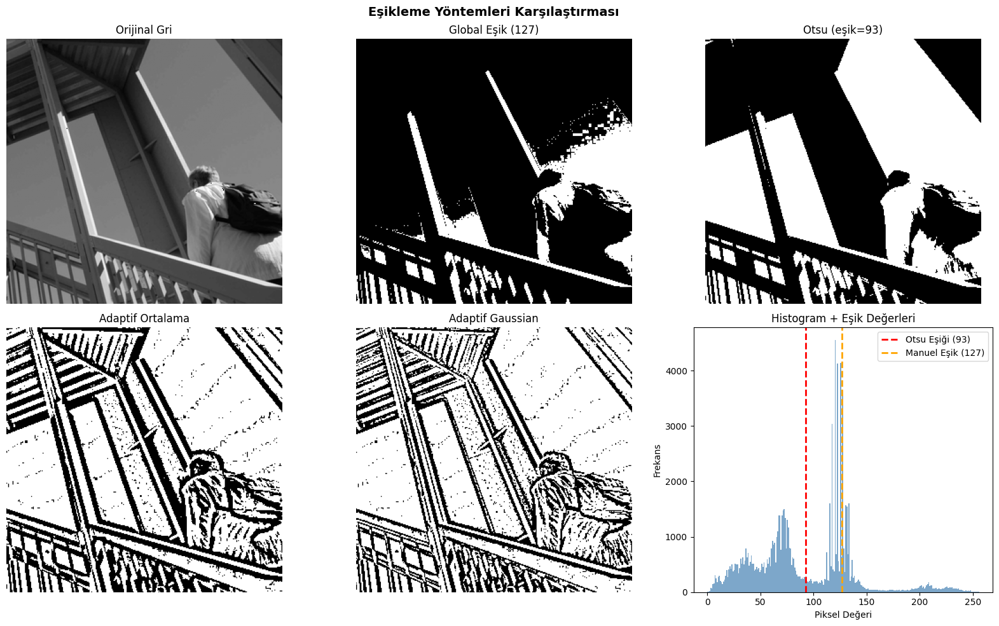

In [15]:
# Eşikleme için küçük görüntü üzerinde çalış
test = img_gray_raw[100:400, 200:700]   # İlgi alanını kırp

# ── 1. Global (Manuel) Eşikleme ─────────────────────────────────────────────
# 127 değerinden büyük piksel → 255 (beyaz), küçük piksel → 0 (siyah)
_, thresh_global = cv2.threshold(test, 127, 255, cv2.THRESH_BINARY)
# Dönüş değerleri: (kullanılan_eşik, eşiklenmiş_görüntü)

# ── 2. Otsu Yöntemi ──────────────────────────────────────────────────────────
# Histogram analizi ile optimal eşiği otomatik bulur
otsu_val, thresh_otsu = cv2.threshold(test, 0, 255, 
                                       cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# THRESH_OTSU bayrağı: eşik değeri=0 verilse de Otsu kendi hesaplar
print(f"Otsu'nun hesapladığı eşik değeri: {otsu_val:.0f}")

# ── 3. Adaptif Ortalama Eşikleme ─────────────────────────────────────────────
# Her 11×11 piksel bölgesi için yerel ortalamayı hesaplar, C değeri çıkarır
thresh_adapt_mean = cv2.adaptiveThreshold(
    test, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,       # Yerel ortalama kullan
    cv2.THRESH_BINARY,
    blockSize=11,                      # Komşuluk pencere boyutu (tek sayı olmalı)
    C=2                                # Ortalamadan çıkarılacak sabit değer
)

# ── 4. Adaptif Gaussian Eşikleme ─────────────────────────────────────────────
# Gaussian ağırlıklı ortalama kullanır → daha yumuşak sonuç
thresh_adapt_gauss = cv2.adaptiveThreshold(
    test, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,   # Gaussian ağırlıklı ortalama kullan
    cv2.THRESH_BINARY,
    blockSize=11,
    C=2
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0,0].imshow(test, cmap='gray');             axes[0,0].set_title("Orijinal Gri");           axes[0,0].axis('off')
axes[0,1].imshow(thresh_global, cmap='gray');    axes[0,1].set_title("Global Eşik (127)");      axes[0,1].axis('off')
axes[0,2].imshow(thresh_otsu, cmap='gray');      axes[0,2].set_title(f"Otsu (eşik={otsu_val:.0f})"); axes[0,2].axis('off')
axes[1,0].imshow(thresh_adapt_mean, cmap='gray');axes[1,0].set_title("Adaptif Ortalama");       axes[1,0].axis('off')
axes[1,1].imshow(thresh_adapt_gauss, cmap='gray');axes[1,1].set_title("Adaptif Gaussian");     axes[1,1].axis('off')

# Histogram ile Otsu eşiğini göster
axes[1,2].hist(test.flatten(), 256, [0,256], color='steelblue', alpha=0.7)
axes[1,2].axvline(x=otsu_val, color='red', linewidth=2, linestyle='--', label=f"Otsu Eşiği ({otsu_val:.0f})")
axes[1,2].axvline(x=127, color='orange', linewidth=2, linestyle='--', label="Manuel Eşik (127)")
axes[1,2].set_title("Histogram + Eşik Değerleri")
axes[1,2].legend()
axes[1,2].set_xlabel("Piksel Değeri")
axes[1,2].set_ylabel("Frekans")

plt.suptitle("Eşikleme Yöntemleri Karşılaştırması", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🔵 Bölüm 10 — Kontur Tespiti ve Nesne Analizi

**Kontur**: Aynı yoğunluktaki sürekli piksellerin sınır eğrisi — nesne şeklini tanımlar.


Bulunan toplam kontur sayısı: 61
Alan > 200 px² olan konturlar: 19


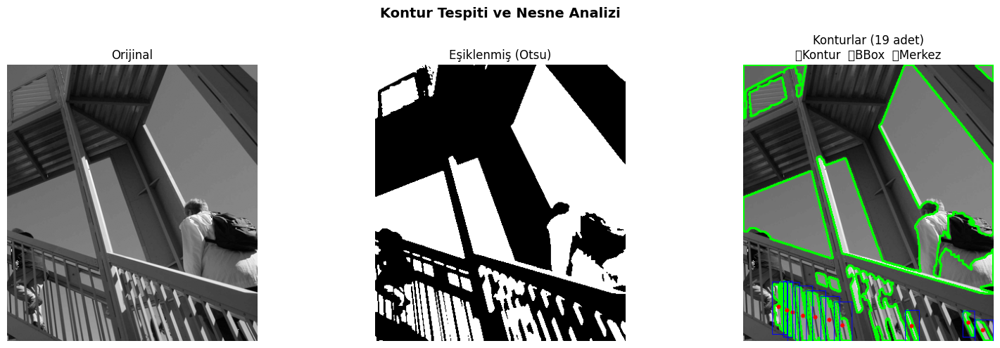

In [16]:
# ── Kontur tespiti için görüntü hazırla ──────────────────────────────────────
prep = img_gray_raw[50:450, 150:750]     # Çalışma bölgesini seç
prep_blur = cv2.GaussianBlur(prep, (5, 5), 0)  # Gürültüyü azalt
_, prep_thresh = cv2.threshold(prep_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# ── Kontur Bul ────────────────────────────────────────────────────────────────
contours, hierarchy = cv2.findContours(
    prep_thresh,
    cv2.RETR_EXTERNAL,        # Sadece dış konturları al (iç içe olanları değil)
    cv2.CHAIN_APPROX_SIMPLE   # Fazladan noktaları sıkıştır (hafıza tasarrufu)
)
print(f"Bulunan toplam kontur sayısı: {len(contours)}")

# ── Büyük konturları filtrele ─────────────────────────────────────────────────
min_area = 200                           # Minimum alan eşiği (piksel²)
large_contours = [c for c in contours if cv2.contourArea(c) > min_area]
print(f"Alan > {min_area} px² olan konturlar: {len(large_contours)}")

# ── Konturları görüntü üzerine çiz ───────────────────────────────────────────
canvas = cv2.cvtColor(prep, cv2.COLOR_GRAY2BGR)  # Gri → BGR (renk çizim için)
cv2.drawContours(canvas, large_contours, -1, (0, 255, 0), 2)  # Yeşil, 2px kalın

# ── Bounding Box ve Merkez Noktası Ekle ──────────────────────────────────────
for i, cnt in enumerate(large_contours[:10]):   # İlk 10 konturu analiz et
    area = cv2.contourArea(cnt)                  # Kontur alanı (px²)
    perimeter = cv2.arcLength(cnt, closed=True)  # Kontur çevre uzunluğu
    
    # Bounding rectangle: konturun etrafına dikdörtgen çiz
    x, y, w, h = cv2.boundingRect(cnt)           # Sol üst köşe + genişlik/yükseklik
    cv2.rectangle(canvas, (x, y), (x+w, y+h), (255, 0, 0), 1)  # Mavi dikdörtgen
    
    # Merkez noktası: Momentler ile hesapla
    M_cnt = cv2.moments(cnt)                     # Kontur momentlerini hesapla
    if M_cnt['m00'] != 0:                        # Alan sıfır değilse
        cx = int(M_cnt['m10'] / M_cnt['m00'])    # X merkezi = m10/m00
        cy = int(M_cnt['m01'] / M_cnt['m00'])    # Y merkezi = m01/m00
        cv2.circle(canvas, (cx, cy), 3, (0, 0, 255), -1)  # Kırmızı merkez noktası

canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)  # BGR → RGB (görüntüleme için)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(prep, cmap='gray');        axes[0].set_title("Orijinal");          axes[0].axis('off')
axes[1].imshow(prep_thresh, cmap='gray'); axes[1].set_title("Eşiklenmiş (Otsu)"); axes[1].axis('off')
axes[2].imshow(canvas_rgb);               axes[2].set_title(f"Konturlar ({len(large_contours)} adet)\n🟢Kontur  🔵BBox  🔴Merkez"); axes[2].axis('off')

plt.suptitle("Kontur Tespiti ve Nesne Analizi", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 🤖 Bölüm 11 — Özellik Çıkarımı ve Makine Öğrenmesi ile Sınıflandırma

Gerçek veri seti: **Sklearn Digits** — 1797 adet el yazısı rakam (0-9).

**Pipeline:**
1. Veri setini yükle → 2. Görselleştir → 3. Özellik çıkar → 4. Eğit → 5. Değerlendir


Toplam görüntü sayısı : 1797
Görüntü boyutu        : 8×8 piksel
Piksel değer aralığı  : [0, 16]
Sınıflar              : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]



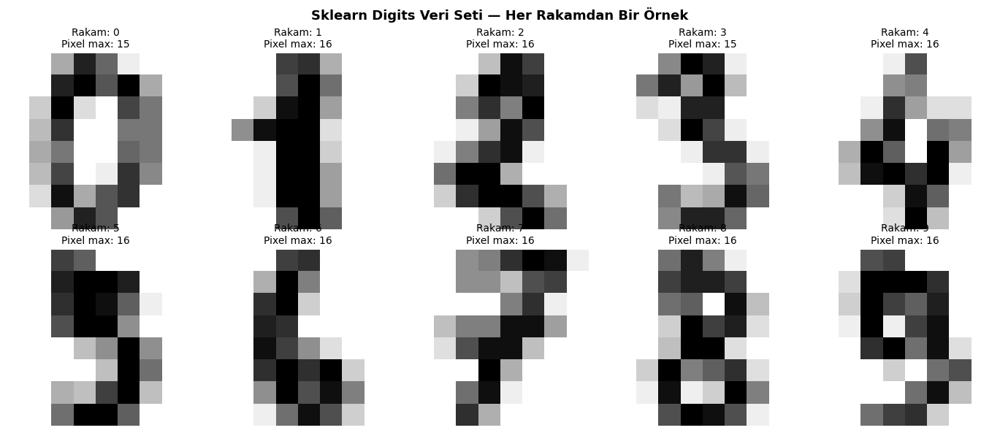

In [17]:
# ── El yazısı rakam veri setini keşfet ───────────────────────────────────────
print(f"Toplam görüntü sayısı : {X_digits.shape[0]}")
print(f"Görüntü boyutu        : {X_digits.shape[1]}×{X_digits.shape[2]} piksel")
print(f"Piksel değer aralığı  : [{X_digits.min():.0f}, {X_digits.max():.0f}]")
print(f"Sınıflar              : {sorted(np.unique(y_digits).tolist())}")
print()

# Her rakamdan birer örnek göster
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for digit in range(10):                              # 0'dan 9'a kadar
    idx = np.where(y_digits == digit)[0][0]          # O rakamın ilk indeksini bul
    ax = axes[digit // 5][digit % 5]                 # 2 satır × 5 sütun düzeni
    ax.imshow(X_digits[idx], cmap='gray_r')          # Ters gri (siyah zemin)
    ax.set_title(f"Rakam: {digit}\nPixel max: {X_digits[idx].max():.0f}", fontsize=10)
    ax.axis('off')

plt.suptitle("Sklearn Digits Veri Seti — Her Rakamdan Bir Örnek", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [18]:
# ── Görüntüleri Düzleştir (Flatten) ──────────────────────────────────────────
# ML modelleri 2D matris değil 1D vektör bekler
# 8×8 piksel görüntü → 64 özellikli vektör
X_flat = X_digits.reshape(X_digits.shape[0], -1)   # (1797, 8, 8) → (1797, 64)
print(f"Orijinal şekil : {X_digits.shape}")
print(f"Düzleştirilmiş : {X_flat.shape}")

# ── Eğitim / Test Bölmesi ─────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y_digits,
    test_size=0.25,       # %25 test, %75 eğitim
    random_state=42,      # Tekrar üretilebilirlik için sabit rastgele tohum
    stratify=y_digits     # Her sınıftan eşit oranda örnekle
)
print(f"\nEğitim seti   : {X_train.shape[0]} örnek")
print(f"Test seti      : {X_test.shape[0]} örnek")

# ── Özellik Normalizasyonu ────────────────────────────────────────────────────
# Piksel değerleri 0-16 arası; StandardScaler ile ortalama=0, std=1 yap
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # Eğitim setinde fit+transform
X_test_scaled  = scaler.transform(X_test)        # Test setinde sadece transform (veri sızıntısı önleme)
print(f"\nNormalizasyon sonrası ortalama: {X_train_scaled.mean():.4f}")
print(f"Normalizasyon sonrası std dev : {X_train_scaled.std():.4f}")


Orijinal şekil : (1797, 8, 8)
Düzleştirilmiş : (1797, 64)

Eğitim seti   : 1347 örnek
Test seti      : 450 örnek

Normalizasyon sonrası ortalama: -0.0000
Normalizasyon sonrası std dev : 0.9763


In [19]:
# ── KNN Modeli Eğit ───────────────────────────────────────────────────────────
# K-En Yakın Komşu: Yeni örnek, eğitimdeki k en yakın komşusunun sınıfını alır
knn = KNeighborsClassifier(
    n_neighbors=5,        # 5 en yakın komşuya bak
    metric='euclidean',   # Mesafe ölçüsü: Öklid mesafesi
    weights='distance'    # Yakın komşulara daha fazla ağırlık ver
)

knn.fit(X_train_scaled, y_train)   # Modeli eğitim verisiyle eğit
y_pred = knn.predict(X_test_scaled)  # Test seti üzerinde tahmin yap

# ── Doğruluk Hesapla ─────────────────────────────────────────────────────────
accuracy = (y_pred == y_test).mean() * 100   # Doğru tahmin oranı
print(f"=== KNN Sınıflandırma Sonuçları ===")
print(f"Test Doğruluğu: {accuracy:.2f}%")
print()
print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)]))


=== KNN Sınıflandırma Sonuçları ===
Test Doğruluğu: 96.44%

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.96      0.98      0.97        46
           2       0.94      1.00      0.97        44
           3       0.98      0.98      0.98        46
           4       0.98      0.93      0.95        45
           5       0.98      0.96      0.97        46
           6       0.98      1.00      0.99        45
           7       0.92      0.98      0.95        45
           8       0.97      0.91      0.94        43
           9       0.95      0.91      0.93        45

    accuracy                           0.96       450
   macro avg       0.96      0.96      0.96       450
weighted avg       0.97      0.96      0.96       450



Toplam yanlis tahmin: 16/450


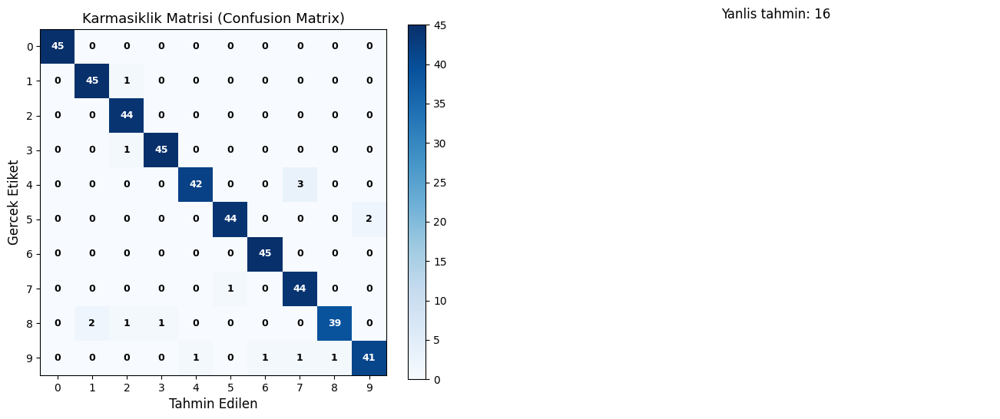

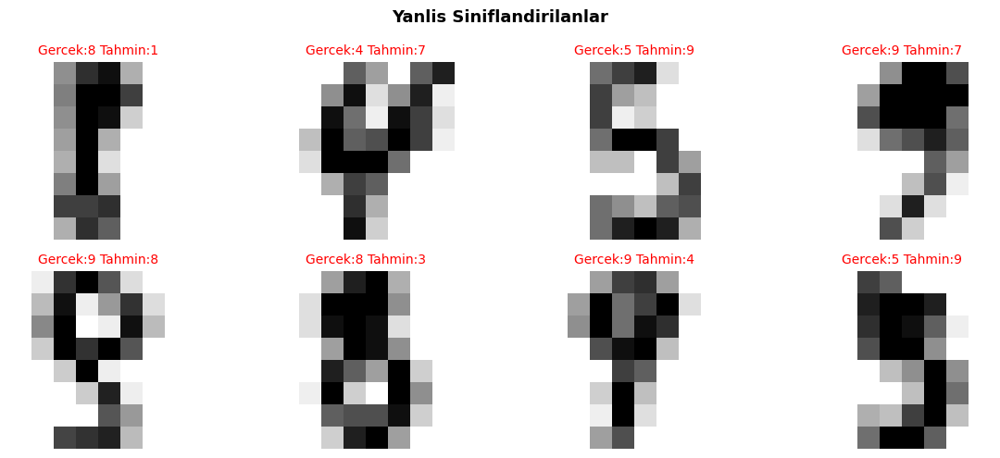

<Figure size 640x480 with 0 Axes>

In [20]:
# Karmasiklik Matrisi (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)   # Gercek vs tahmin karsilastirmasi

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xlabel("Tahmin Edilen", fontsize=12)
axes[0].set_ylabel("Gercek Etiket", fontsize=12)
axes[0].set_title("Karmasiklik Matrisi (Confusion Matrix)", fontsize=13)
axes[0].set_xticks(range(10));  axes[0].set_xticklabels(range(10))
axes[0].set_yticks(range(10));  axes[0].set_yticklabels(range(10))
plt.colorbar(im, ax=axes[0])

for i in range(10):
    for j in range(10):
        color = 'white' if cm[i,j] > cm.max()/2 else 'black'
        axes[0].text(j, i, str(cm[i,j]), ha='center', va='center',
                    color=color, fontsize=9, fontweight='bold')

# Yanlis siniflandirilanlar
wrong_mask = y_pred != y_test
wrong_indices = np.where(wrong_mask)[0]
print(f"Toplam yanlis tahmin: {wrong_mask.sum()}/{len(y_test)}")

axes[1].axis('off')
axes[1].set_title(f"Yanlis tahmin: {wrong_mask.sum()}", fontsize=12)

if len(wrong_indices) >= 8:
    sub_fig, sub_axes = plt.subplots(2, 4, figsize=(12, 5))
    for ax, idx in zip(sub_axes.flatten(), wrong_indices[:8]):
        flat_img = X_test[idx]
        real_img = flat_img.reshape(8, 8)
        ax.imshow(real_img, cmap='gray_r')
        ax.set_title("Gercek:" + str(y_test[idx]) + " Tahmin:" + str(y_pred[idx]),
                    color='red', fontsize=10)
        ax.axis('off')
    plt.suptitle("Yanlis Siniflandirilanlar", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

plt.tight_layout()
plt.show()


## 🧮 Bölüm 12 — El Yapımı Özellik Çıkarımı: HOG (Histogram of Oriented Gradients)

HOG: Görüntüdeki kenar yönlerinin istatistiksel dağılımını çıkarır. YOLO gibi modern
nesne dedektörlerinin atası olan güçlü bir el yapımı özelliktir.


HOG Özellik Vektörleri:
  Görüntü 0 (rakam=0): 144 özellik
  Görüntü 1 (rakam=1): 144 özellik
  Görüntü 2 (rakam=2): 144 özellik
  Görüntü 3 (rakam=3): 144 özellik
  Görüntü 4 (rakam=4): 144 özellik


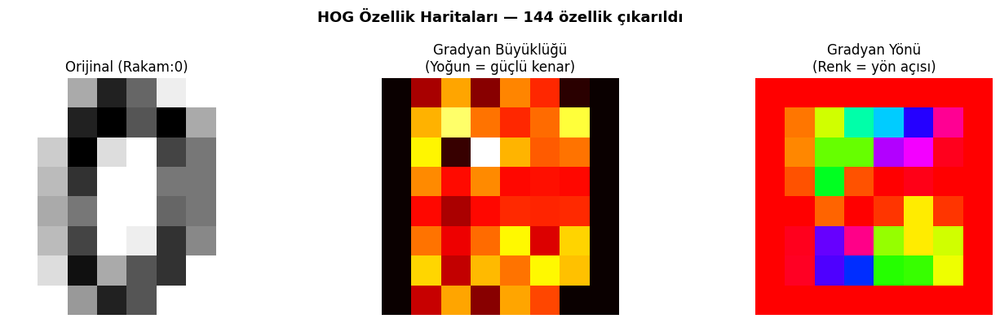

In [21]:
# ── HOG Özellik Çıkarımı — Adım Adım ─────────────────────────────────────────
def compute_hog_features(image, cell_size=2, n_bins=8):
    """
    Basit HOG özellik çıkarımı.
    cell_size: Her hücrenin piksel boyutu (cell_size × cell_size)
    n_bins   : Gradient yönü histogram kutu sayısı
    """
    # Adım 1: Gradyanları hesapla (Sobel)
    gx = cv2.Sobel(image.astype(float), cv2.CV_64F, 1, 0, ksize=1)  # X gradyanı
    gy = cv2.Sobel(image.astype(float), cv2.CV_64F, 0, 1, ksize=1)  # Y gradyanı
    
    # Adım 2: Büyüklük ve yön hesapla
    magnitude = np.sqrt(gx**2 + gy**2)           # Gradyan büyüklüğü
    angle = np.arctan2(gy, gx) * 180 / np.pi     # Açı (-180° ile +180°)
    angle = angle % 180                            # 0-180° aralığına normalize et

    # Adım 3: Her hücre için histogram oluştur
    h, w = image.shape
    n_cells_y = h // cell_size                    # Dikey hücre sayısı
    n_cells_x = w // cell_size                    # Yatay hücre sayısı
    
    histograms = np.zeros((n_cells_y, n_cells_x, n_bins))   # Histogram dizisi
    
    for i in range(n_cells_y):
        for j in range(n_cells_x):
            # Her hücrenin büyüklük ve açılarını al
            cell_mag = magnitude[i*cell_size:(i+1)*cell_size, j*cell_size:(j+1)*cell_size]
            cell_ang = angle[i*cell_size:(i+1)*cell_size, j*cell_size:(j+1)*cell_size]
            # Histogram: açıya göre büyüklükleri sepetlere dağıt
            hist, _ = np.histogram(cell_ang, bins=n_bins, range=(0, 180), weights=cell_mag)
            histograms[i, j, :] = hist
    
    return histograms.flatten(), magnitude, angle  # Düzleştirilmiş özellik vektörü

# 5 örnek görüntü için HOG uygula
sample_imgs = X_digits[:5]                          # İlk 5 görüntü
print("HOG Özellik Vektörleri:")
for i, img in enumerate(sample_imgs):
    hog_feat, mag, ang = compute_hog_features(img, cell_size=2, n_bins=9)
    print(f"  Görüntü {i} (rakam={y_digits[i]}): {len(hog_feat)} özellik")

# Bir görüntüyü detaylı görselleştir
sample = X_digits[0]
hog_feat, mag, ang = compute_hog_features(sample, cell_size=2, n_bins=9)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sample, cmap='gray_r');   axes[0].set_title(f"Orijinal (Rakam:{y_digits[0]})"); axes[0].axis('off')
axes[1].imshow(mag, cmap='hot');         axes[1].set_title("Gradyan Büyüklüğü\n(Yoğun = güçlü kenar)"); axes[1].axis('off')
axes[2].imshow(ang, cmap='hsv');         axes[2].set_title("Gradyan Yönü\n(Renk = yön açısı)");    axes[2].axis('off')

plt.suptitle(f"HOG Özellik Haritaları — {len(hog_feat)} özellik çıkarıldı", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 🎓 Özet ve Öğrenilen Kavramlar

| # | Kavram | Araç |
|---|--------|------|
| 1 | Piksel, kanal, dtype | NumPy |
| 2 | RGB, Grayscale, HSV, LAB dönüşümleri | OpenCV |
| 3 | Kırpma, yeniden boyutlandırma, döndürme | NumPy, OpenCV |
| 4 | Histogram analizi ve eşitleme | NumPy, OpenCV |
| 5 | Box, Gaussian, Medyan, Bilateral filtreler | OpenCV |
| 6 | Sobel, Laplacian, Canny kenar tespiti | OpenCV |
| 7 | Erosion, Dilation, Opening, Closing | OpenCV |
| 8 | Global, Otsu, Adaptif eşikleme | OpenCV |
| 9 | Kontur tespiti, bounding box, merkez | OpenCV |
| 10 | KNN ile sınıflandırma, Confusion Matrix | Scikit-learn |
| 11 | HOG özellik çıkarımı | NumPy |

---

## 🚀 Sonraki Adımlar

- **Derin Öğrenme**: CNN (Convolutional Neural Network) ile otomatik özellik öğrenimi
- **Transfer Learning**: ResNet, VGG, EfficientNet gibi önceden eğitilmiş modeller
- **Nesne Tespiti**: YOLO, Faster R-CNN
- **Semantic Segmentation**: Piksel düzeyinde sınıflandırma
- **Kütüphaneler**: `torchvision`, `tensorflow.keras`, `albumentations`

> 📌 **Kaggle Veri Setleri için:** https://www.kaggle.com/datasets?tags=13207-Image+Data
